# Logistic Regression — Will This Person Have Insurance?

So far we predicted **numbers** (delivery time, salary) with linear regression. But lots of real questions are **yes / no**:

- Will this customer buy? 
- Is this email spam? 
- Does this person **have insurance**?

That's **classification**, and the go-to starter model is **Logistic Regression**. Despite the name, it predicts a **category (0 or 1)**, not a number — it does this by estimating the **probability** of "yes" and then rounding.

We'll predict whether someone **has insurance** based only on their **age**.

## The data

Two columns:
- `age` — the person's age
- `has_insurance` — `1` = yes, `0` = no

In [1]:
import pandas as pd

df = pd.read_csv("insurance_data.csv")
df.head()

,age,has_insurance
0,18,0
1,19,0
2,20,0
3,22,0
4,23,0


## Look at the data first

Plot age against `has_insurance`. Every dot sits at either **0** or **1**.

Notice it's **messy** — some people in their 20s already have insurance, and some folks in their 50s–60s don't. There's no clean line separating the two groups. 🤷 Real human behavior is like that! So logistic regression won't hunt for a perfect cutoff. Instead it learns how the **probability of "yes" rises with age** — a gentle trend, not a hard rule.

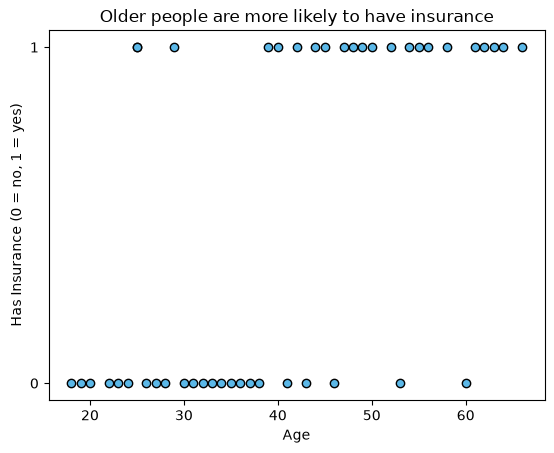

In [2]:
import matplotlib.pyplot as plt

plt.scatter(df.age, df.has_insurance, color='#5BB8E8', edgecolor='k')
plt.xlabel("Age")
plt.ylabel("Has Insurance (0 = no, 1 = yes)")
plt.title("Older people are more likely to have insurance")
plt.yticks([0, 1])
plt.show()

## Step 1 — Split into training and test sets

Same honest habit as before: train on most of the data, keep some aside to test on.

In [3]:
from sklearn.model_selection import train_test_split

X = df[['age']]
y = df.has_insurance

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print("Training rows:", X_train.shape[0])
print("Testing rows: ", X_test.shape[0])

Training rows: 36
Testing rows:  9


## Step 2 — Train the Logistic Regression model

In [4]:
from sklearn.linear_model import LogisticRegression

model = LogisticRegression()
model.fit(X_train, y_train)

,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag', 'saga' or 'liblinear' to shuffle thedata. See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following aspects:- 'lbfgs' is a good default sol

## Step 3 — Make predictions

`predict()` returns the **class** (0 or 1). Let's ask about three people: a 22-year-old, a 45-year-old, and a 60-year-old.

In [5]:
ages = pd.DataFrame({'age': [22, 45, 60]})
preds = model.predict(ages)

for age, pred in zip(ages.age, preds):
    answer = 'YES, has insurance' if pred == 1 else 'no insurance'
    print(f"Age {age}: {answer}")

Age 22: no insurance
Age 45: YES, has insurance
Age 60: YES, has insurance


## Step 4 — Peek at the probabilities

Under the hood the model isn't 100% sure — it computes a **probability** and then rounds at 0.5. `predict_proba()` shows that confidence. The second number is the probability of **has_insurance = 1**.

In [6]:
probs = model.predict_proba(ages)

for age, p in zip(ages.age, probs):
    print(f"Age {age}: P(no) = {p[0]:.2f}, P(has insurance) = {p[1]:.2f}")

Age 22: P(no) = 0.89, P(has insurance) = 0.11
Age 45: P(no) = 0.33, P(has insurance) = 0.67
Age 60: P(no) = 0.07, P(has insurance) = 0.93


See how the probability of having insurance **climbs with age** — barely likely at 22, a confident yes by 60. That smooth 0→1 climb is the famous **S-shaped (sigmoid) curve** logistic regression is built on.

In [7]:
model.coef_

array([[0.121951]])

In [8]:
model.intercept_

array([-4.78489728])

In [9]:
import math
def sigmoid(x):
  return 1 / (1 + math.exp(-x))

In [13]:
def prediction_function(age):
    z = model.coef_[0][0] * age + model.intercept_[0] 
    y = sigmoid(z)
    return y

prediction_function(35)    

0.3736447757193444

**Here  0.37 is less than 0.5 which means this person (with age 35) will not buy insurance**

In [14]:
prediction_function(45)

0.6688299683319732

**Here  0.6688 is > 0.5 which means this person (with age 45) will buy insurance**

## Step 5 — How accurate is the model?

For classification, `score()` returns **accuracy** — the fraction of test people it labelled correctly (closer to `1` = better).

In [7]:
accuracy = model.score(X_test, y_test)
print(f"Accuracy on the test set: {accuracy:.2f}")

Accuracy on the test set: 0.78


Not a perfect 1.0 — and that's **expected**. Because our data is realistically messy (early-bird 20-somethings, uninsured 60-somethings), no model can be right every single time from age alone. Getting most of them right by learning the **overall trend** is exactly what a good, honest classifier does. In practice you'd add more features (income, family, health) to push accuracy higher.

## Step 6 — Classification Report

Classification report calculates precision, recall, f1-score and accuracy for the model predictions

In [15]:
from sklearn.metrics import classification_report

y_pred = model.predict(X_test)

report = classification_report(y_test, y_pred)
print(report)

              precision    recall  f1-score   support

           0       1.00      0.60      0.75         5
           1       0.67      1.00      0.80         4

    accuracy                           0.78         9
   macro avg       0.83      0.80      0.78         9
weighted avg       0.85      0.78      0.77         9



## Step 7 — Confusion matrix

Accuracy gives one number, but it hides **what kind** of mistakes the model makes. A **confusion matrix** breaks the test predictions into four buckets:

|                     | Predicted: no | Predicted: yes |
|---------------------|:-------------:|:--------------:|
| **Actually no**     | ✅ True Negative | ❌ False Positive |
| **Actually yes**    | ❌ False Negative | ✅ True Positive |

The diagonal (top-left → bottom-right) is where the model got it **right**; off-diagonal cells are the mistakes.

In [8]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

y_pred = model.predict(X_test)
cm = confusion_matrix(y_test, y_pred)
print(cm)

[[3 2]
 [0 4]]


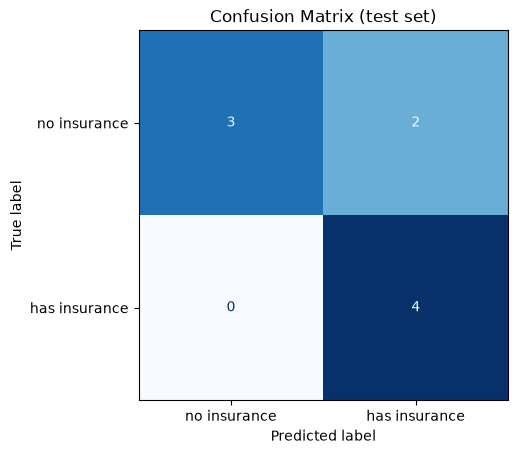

In [9]:
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=['no insurance', 'has insurance']
)
disp.plot(cmap='Blues', colorbar=False)
plt.title('Confusion Matrix (test set)')
plt.show()

Read it like this:
- **Top-left** — people who *don't* have insurance and the model correctly said "no"
- **Bottom-right** — people who *do* have insurance and the model correctly said "yes"
- **Top-right** — model said "yes" but they actually have none (**false alarm**)
- **Bottom-left** — model said "no" but they actually have insurance (**missed it**)

For something like insurance, the two mistake types can matter very differently — which is why we look past a single accuracy number.

## Recap
- **Logistic Regression** predicts a **category (0/1)**, not a number — it's for **classification**
- `model.predict(X)` → the yes/no answer
- `model.predict_proba(X)` → the probability behind that answer
- `model.score(X_test, y_test)` → **accuracy** (fraction predicted correctly)
- A **confusion matrix** shows *what kind* of mistakes it makes (false alarms vs misses)
- The same idea powers spam filters, fraud detection, and "will they buy?" models